# Stage 1: how beam shift and tilt at the specimen displace the beam on the camera, across projection-lens settings

The cells below drive the microscope through PyJEM and record how far beam shifts (CLA1) and tilts (CLA2)
displace the beam on the camera at 21 lens settings (sections 1–7), fit a model of the projection
lenses to those displacements (section 8), and test it at lens settings it never saw (section 9).
Every cell that changes the microscope is first run as a **dry run**: it reads the microscope but
changes nothing, and prints each change it would make. The session tools are in `../pyjem_session.py`.

**One switch in section 1 chooses the microscope.** `on_microscope = True`: the real NEOARM through
PyJEM. `on_microscope = False` (as saved here): the virtual NEOARM, TemGym's simulated microscope
with hidden lenses behind PyJEM's names, at 200 kV like the real one. The virtual one differs from the real NEOARM in
three ways: its hidden lenses are a model fitted to the NEOARM's lens table, not the real lenses; its
lenses settle instantly (`settle_s` 0 instead of 2 s); and its camera image is mirrored, which the fit
has to find by itself.

**Recording (sections 1–7) needs only numpy and PyJEM**, so it runs on the microscope PC as it is.
The fit (section 8) needs TemGym and JAX: copy the recording folder to a computer that has them.

In [1]:
import json
import sys
import time
from pathlib import Path

import numpy as np

sys.path.append("..")
from pyjem_session import Session, camera_among, check_pyjem, find_beam, newest_file_in, read_frame, show_frame   # numpy and PyJEM only

## 1. Connecting to the microscope

`on_microscope = True`: the real NEOARM. PyJEM gives `TEM3` (lenses, deflectors, modes); the camera
is the NEOARM's SightX, through PyJEM's `sightx` package at the camera PC's address. That package has
the same calls as PyJEM's `detector` package, so it takes `detector`'s place. The frame's size comes
from the camera's settings (its imaging area); if they do not give it, set `frame_shape` = (height,
width). Lenses are given 2 s to settle; recordings go to `output/stage1_neoarm/`, each session in a
new folder named by its date and time, so nothing recorded before is ever overwritten.

`on_microscope = False`: the virtual NEOARM, built from one ground-truth file
(`../virtual_neoarm/virtual_neoarm.json`, worked out once in `../virtual_neoarm/design.ipynb`). It
starts as left at the console: 200 kV, MAG at the 40k row, camera binning 8 at 10 ms, specimen out.
Recordings go to `output/stage1_simulated/`.

`show_frames` draws one sample frame at the end of each cell that takes frames, with the beam
centres found marked; it is off at the microscope, where matplotlib may not be installed.

If the camera is not reachable through PyJEM (the cells of section 2 will say), use the camera's own
software to save every frame into a folder and set `take_frame = newest_file_in("D:/camera_frames")`:
each frame is then the newest file there.

In [2]:
on_microscope = False    # True: the real NEOARM through PyJEM. False: the simulated NEOARM (needs TemGym).

if on_microscope:
    from PyJEM import TEM3
    from PyJEM import sightx as detector                 # the SightX camera: the same calls as PyJEM's detector package
    detector.set_ip("172.17.41.1")                       # the camera PC
    camera_name = "sightx"
    frame_shape = None                                   # None: from the camera's settings; or (height, width)
    frame_dtype = None                                   # None: 2 or 4 bytes per pixel, signed; or e.g. "<u2"
    settle_s = 2                                         # s for the lenses to settle after a change
    output = "output/stage1_neoarm"
else:
    import os
    os.environ["JAX_PLATFORMS"] = "cpu"                  # TemGym's JAX on the CPU (before it is imported): no GPU needed
    import temgym_core
    from temgym_core.pyjem_simulator import SimulatedMicroscope
    temgym_core.enable_x64()
    microscope = SimulatedMicroscope.from_file("../virtual_neoarm/virtual_neoarm.json", ht_v=200e3)
    TEM3, detector = microscope.pyjem()
    camera_name = None                                   # None: the attached detector that is not a STEM detector
    frame_shape = None
    frame_dtype = None
    settle_s = 0                                         # the simulated lenses settle instantly
    output = "output/stage1_simulated"

take_frame = None                                        # None: frames from PyJEM's camera
show_frames = not on_microscope                          # one sample frame per cell (needs matplotlib)

## 2. Checking the camera and the beam before changing anything

First, the Python version, which of the PyJEM calls the session uses this PyJEM has (an older PyJEM
may lack some), the attached detectors and which one is the camera. This changes nothing.

In [3]:
missing = check_pyjem(TEM3=TEM3, detector=detector, camera_name=camera_name)

Python 3.12.12
TEM3.Lens3: all there
TEM3.Def3: all there
TEM3.EOS3: all there
TEM3.HT3: all there
detector: all there
attached detectors: ['camera']
the camera among them: camera


Then the camera on its own, straight through PyJEM: its settings, and one frame read as the
session will read it (its size, pixel type and range of values). Without `camera_name`, the camera
is the attached detector that is not a STEM detector (PyJEM lists HAADF, BF, ... with the camera).

In [4]:
if take_frame is None:
    camera = detector.Detector(camera_name or camera_among(detector.get_attached_detector()))
    try:
        print("camera settings:", camera.get_detectorsetting())
    except Exception as error:
        print("no camera settings from PyJEM:", error, "(set frame_shape in section 1)")
    frame, dtype = read_frame(camera, frame_dtype, frame_shape)
    print(f"one frame: {frame.shape[1]} x {frame.shape[0]} px, read as {dtype}, values {frame.min()} to {frame.max()}")
else:
    print("frames come from take_frame, not through PyJEM")

camera settings: {'ImagingArea': {'X': 0, 'Y': 0, 'Width': 256, 'Height': 256}, 'BinningSize': 8, 'ExposureTimeValue': 10000.0, 'GainIndex': 0, 'OffsetIndex': 0, 'frameIntegration': 1, 'scanMode': 0, 'OutputImageInformation': {'DataBits': 32, 'ImageSize': 262144, 'PixelsPerMeter': 9090.90909090909}}


one frame: 256 x 256 px, read as <i4, values -8 to 401632


Then the session. Opening it changes nothing: it notes the microscope's state, so that
`session.restore()` can put it back. **The session is a dry run unless a block explicitly allows
changes**: anywhere outside a `with session.dry_run(False):` block, whatever it is asked to do is
only printed ("would set IL1 21534 -> 23534"). Here it takes one frame (`session.frame`) and
finds the beam in it (`find_beam`; until a dark frame is taken, it estimates the dark level from the frame itself).

200 kV, X40000; IL1 41782, IL2 24862, IL3 35544, PL1 64000; CLA1 [32768, 32768], CLA2 [32768, 32768]


first frame: 256 x 256 px, read as <i4, values -8 to 401734 (if bright pixels show as large negative numbers, open the session with dtype='<u2')


beam at (+0.0, +0.0) px from the centre, rms 6.2 px
problems: none


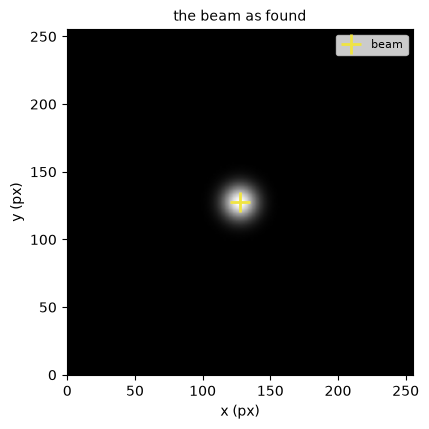

In [5]:
LENSES = ("IL1", "IL2", "IL3", "PL1")

session = Session(TEM3=TEM3, detector=detector, take_frame=take_frame, lenses=LENSES, settle_s=settle_s,
                  camera_name=camera_name, frame_shape=frame_shape, dtype=frame_dtype,
                  folder=f"{output}/projection_response_{time.strftime('%Y-%m-%d_%H%M%S')}")    # a new folder each time

frame = session.frame()
beam = find_beam(frame=frame, background=session.dark_level)
print(f"beam at ({beam.centre.real:+.1f}, {beam.centre.imag:+.1f}) px from the centre, rms {beam.rms:.1f} px")
print("problems:", "; ".join(beam.problems) or "none")

if show_frames:
    show_frame(frame, beams=[("beam", beam)], title="the beam as found")

Every cell below that changes the microscope looks like this:

```python
dry_run = True           # True: only print what this cell would do. False: do it.

with session.dry_run(dry_run):
    ...
```

Run it with `True`, read what it prints, then set `False` and run it again. After the block the
session is a dry run again, whatever happened inside. In a dry run nothing changes, so any
displacements it prints are not real; the "would ..." lines are what matters. (The sample frames
are real frames of the microscope as it is, so in a dry run the "deflected" beam has not moved.) The cells
are saved with `True`, so running the notebook as it is changes nothing; with nothing recorded,
the fit and the figures just say so.

## 3. Reading the lens settings of the 40k MAG row and the 40 cm DIFF row

The experiment works around two starting points: the 40k MAG row (where the microscope is now) and
the DIFF row at 40 cm (IL1–PL1 as the console sets them in DIFF; a dry run cannot know those, it
does not switch). Then IL1–PL1 go under free-lens control at the 40k values, and a dark frame is
taken with the beam blanked.

In [6]:
dry_run = True           # True: only print what this cell would do. False: do it.

lenses_at = {}                                   # IL1-PL1 DAC values at each starting point

with session.dry_run(dry_run):
    lenses_at["40k"] = session.lenses_now()
    session.diffraction(camera_length_cm=40)
    lenses_at["DIFF"] = session.lenses_now()
    session.imaging()

    session.take_over_lenses()
    dark = session.dark_frame()

if show_frames:
    show_frame(dark, title="dark frame (beam blanked)")

lenses_at

DRY RUN: nothing will change


  would switch to DIFF at 40 cm


  (dry run: the DIFF values are known only after switching to DIFF)


  would switch back to MAG


  would switch free-lens control on for IL1, IL2, IL3, PL1 at IL1 41782, IL2 24862, IL3 35544, PL1 64000


  would blank the beam, take a dark frame, unblank


dark frame (beam blanked): no frame (dry run)


{'40k': array([41782., 24862., 35544., 64000.]),
 'DIFF': array([nan, nan, nan, nan])}

## 4. Choosing the deflection sizes for CLA1 (shift) and CLA2 (tilt)

At each starting point, each deflector is deflected by 100 units, then 200, 400, ... until it
displaces the beam by more than 25 px (at most 20 000 units). If the beam leaves the camera, the deflection goes back to
half. These deflection sizes are used, along x and along y, for every lens setting around that starting point.

DRY RUN: nothing will change


40k, CLA1: deflections of 100, 200, 400, ... units (at most 20000) until the beam is displaced by > 25 px
  would deflect CLA1 by +100, +0 units (to [32868, 32768])


   CLA1   100 units: beam displaced   0.0 px
  would deflect CLA1 by +200, +0 units (to [32968, 32768])


   CLA1   200 units: beam displaced   0.0 px
  would deflect CLA1 by +400, +0 units (to [33168, 32768])


   CLA1   400 units: beam displaced   0.0 px
  would deflect CLA1 by +800, +0 units (to [33568, 32768])


   CLA1   800 units: beam displaced   0.0 px
  would deflect CLA1 by +1600, +0 units (to [34368, 32768])


... (29 outputs left out)

   CLA2  3200 units: beam displaced   0.0 px
  would deflect CLA2 by +6400, +0 units (to [39168, 32768])


   CLA2  6400 units: beam displaced   0.0 px
  would deflect CLA2 by +12800, +0 units (to [45568, 32768])


   CLA2 12800 units: beam displaced   0.0 px
  would deflect CLA2 by +20000, +0 units (to [52768, 32768])


   CLA2 20000 units: beam displaced   0.0 px


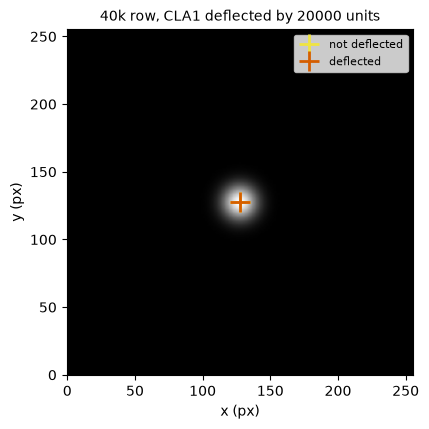

{('40k', 'CLA1'): 20000,
 ('40k', 'CLA2'): 20000,
 ('DIFF', 'CLA1'): 20000,
 ('DIFF', 'CLA2'): 20000}

In [7]:
dry_run = True           # True: only print what this cell would do. False: do it.

deflection_units = {}          # deflection size, per starting point and deflector
displacement_px = {}           # how far that deflection displaces the beam on the camera (x + iy)

with session.dry_run(dry_run):
    for start in ["40k", "DIFF"]:
        session.set_lenses(lenses_at[start])
        frame = session.frame(role="trying a deflection")
        beam_not_deflected = find_beam(frame=frame, background=session.dark_level)

        for deflector in ["CLA1", "CLA2"]:
            print(f"{start}, {deflector}: deflections of 100, 200, 400, ... units (at most 20000) until the beam is displaced by > 25 px")
            deflection = 100
            while True:
                session.deflect(deflector, deflection)
                frame = session.frame(role="trying a deflection")
                beam_deflected = find_beam(frame=frame, background=session.dark_level)
                session.deflect(deflector, 0)
                displacement = beam_deflected.centre - beam_not_deflected.centre
                print(f"   {deflector} {deflection:5d} units: beam displaced {abs(displacement):5.1f} px")
                if start == "40k" and deflector == "CLA1":      # the sample frame shown at the end: the last try here
                    sample = dict(frame=frame, beams=[("not deflected", beam_not_deflected), ("deflected", beam_deflected)],
                                  title=f"40k row, CLA1 deflected by {deflection} units")

                if not beam_deflected.usable:           # off the camera: back to half
                    deflection = deflection // 2
                    break
                if abs(displacement) > 25 or deflection == 20000:
                    break
                deflection = min(2 * deflection, 20000)

            deflection_units[start, deflector] = deflection
            displacement_px[start, deflector] = displacement

if show_frames:
    show_frame(**sample)

deflection_units

## 5. Choosing the step sizes for IL1–IL3 and PL1

At each starting point, each lens is stepped by 250 DAC units, then 500, 1000, ... until the step
clearly changes the displacement from that starting point's stronger deflection (by more than 10 px),
at most 8000 units. The steps go the way the lens has more room in its DAC range (lenses stay between
2000 and 65535): up for most, down for a lens near the top, such as PL1. The step found is then used
up and down, each way cut to the room on that side.

DRY RUN: nothing will change


40k, IL1: steps down of 250, 500, 1000, ... DAC units (at most 8000) until the CLA1 deflection's displacement changes by > 10 px
  would set IL1 nan -> 41532, IL2 nan -> 24862, IL3 nan -> 35544, PL1 nan -> 64000


  would deflect CLA1 by +20000, +0 units (to [52768, 32768])


   IL1  -250: the CLA1 deflection's displacement changed by   0.0 px
  would set IL1 41532 -> 41282


  would deflect CLA1 by +20000, +0 units (to [52768, 32768])


   IL1  -500: the CLA1 deflection's displacement changed by   0.0 px
  would set IL1 41282 -> 40782


... (90 outputs left out)

  would deflect CLA1 by +20000, +0 units (to [52768, 32768])


   PL1 -4000: the CLA1 deflection's displacement changed by   0.0 px
  would set IL1 to its DIFF value (unknown in a dry run), IL2 to its DIFF value (unknown in a dry run), IL3 to its DIFF value (unknown in a dry run), PL1 to its DIFF value (unknown in a dry run)


  would deflect CLA1 by +20000, +0 units (to [52768, 32768])


   PL1 -8000: the CLA1 deflection's displacement changed by   0.0 px
  would set IL1 to its DIFF value (unknown in a dry run), IL2 to its DIFF value (unknown in a dry run), IL3 to its DIFF value (unknown in a dry run), PL1 to its DIFF value (unknown in a dry run)


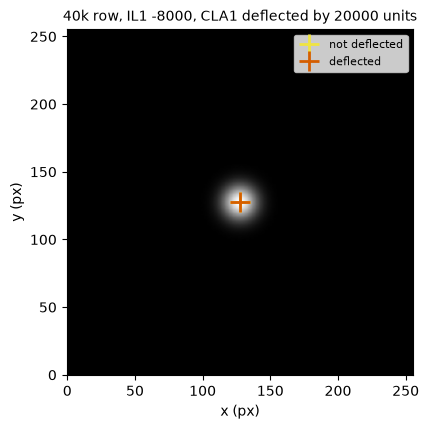

{('40k', 'IL1', 1): 8000,
 ('40k', 'IL1', -1): 8000,
 ('40k', 'IL2', 1): 8000,
 ('40k', 'IL2', -1): 8000,
 ('40k', 'IL3', 1): 8000,
 ('40k', 'IL3', -1): 8000,
 ('40k', 'PL1', 1): 1535,
 ('40k', 'PL1', -1): 8000,
 ('DIFF', 'IL1', 1): 8000,
 ('DIFF', 'IL1', -1): 8000,
 ('DIFF', 'IL2', 1): 8000,
 ('DIFF', 'IL2', -1): 8000,
 ('DIFF', 'IL3', 1): 8000,
 ('DIFF', 'IL3', -1): 8000,
 ('DIFF', 'PL1', 1): 8000,
 ('DIFF', 'PL1', -1): 8000}

In [8]:
dry_run = True           # True: only print what this cell would do. False: do it.

lens_step_units = {}                             # lens step, per starting point, lens and direction (+1 up, -1 down)

with session.dry_run(dry_run):
    for start in ["40k", "DIFF"]:
        # the deflector whose deflection displaces the beam more here is the yardstick
        if abs(displacement_px[start, "CLA1"]) > abs(displacement_px[start, "CLA2"]):
            deflector = "CLA1"
        else:
            deflector = "CLA2"
        deflection = deflection_units[start, deflector]
        displacement_at_start = displacement_px[start, deflector]

        for i, lens in enumerate(LENSES):
            room_up = 65535 - lenses_at[start][i]           # DAC units the lens can go up
            room_down = lenses_at[start][i] - 2000          # and down
            if room_up >= room_down:
                sign, direction, room = +1, "up", room_up
            else:
                sign, direction, room = -1, "down", room_down
            largest_step = int(min(8000, room))
            print(f"{start}, {lens}: steps {direction} of 250, 500, 1000, ... DAC units (at most {largest_step}) "
                  f"until the {deflector} deflection's displacement changes by > 10 px")
            lens_step = 250
            while True:
                lenses = lenses_at[start].copy()
                lenses[i] = lenses[i] + sign * lens_step
                session.set_lenses(lenses)
                frame = session.frame(role="trying a lens step")
                beam_not_deflected = find_beam(frame=frame, background=session.dark_level)
                session.deflect(deflector, deflection)
                frame = session.frame(role="trying a lens step")
                beam_deflected = find_beam(frame=frame, background=session.dark_level)
                session.deflect(deflector, 0)
                displacement = beam_deflected.centre - beam_not_deflected.centre
                change = abs(displacement - displacement_at_start)
                print(f"   {lens} {sign * lens_step:+5d}: the {deflector} deflection's displacement changed by {change:5.1f} px")
                if start == "40k" and lens == "IL1":            # the sample frame shown at the end: the last try here
                    sample = dict(frame=frame, beams=[("not deflected", beam_not_deflected), ("deflected", beam_deflected)],
                                  title=f"40k row, IL1 {sign * lens_step:+d}, {deflector} deflected by {deflection} units")

                if not (beam_not_deflected.usable and beam_deflected.usable):     # beam lost: back to half
                    lens_step = lens_step // 2
                    break
                if change > 10 or lens_step >= largest_step:
                    break
                lens_step = min(2 * lens_step, largest_step)

            # the step found, used up and down: each way at most the room on that side
            lens_step_units[start, lens, +1] = int(min(lens_step, room_up))
            lens_step_units[start, lens, -1] = int(min(lens_step, room_down))

        session.set_lenses(lenses_at[start])

if show_frames:
    show_frame(**sample)

lens_step_units

## 6. Measurement plan: lens settings and deflections

Every lens setting to be measured, and how far each deflector will be deflected there (+ and −, along x
and along y).
Around each starting point: the starting point itself, each lens stepped up and down by its step,
and the starting point again; all with the deflection sizes found for that starting point. Then
the 40k row once more. The repeats of the 40k row give the wobble.

In [9]:
measurement_plan = []

for start in ["40k", "DIFF"]:
    deflections = {"CLA1": deflection_units[start, "CLA1"], "CLA2": deflection_units[start, "CLA2"]}

    measurement_plan.append(dict(name=f"{start} row", lenses=lenses_at[start], deflections=deflections))
    for i, lens in enumerate(LENSES):
        for sign in [+1, -1]:
            lenses = lenses_at[start].copy()
            lenses[i] = lenses[i] + sign * lens_step_units[start, lens, sign]
            name = f"{start} row: {lens} {sign * lens_step_units[start, lens, sign]:+d}"
            measurement_plan.append(dict(name=name, lenses=lenses, deflections=deflections))
    measurement_plan.append(dict(name=f"{start} row", lenses=lenses_at[start], deflections=deflections))

measurement_plan.append(dict(name="40k row", lenses=lenses_at["40k"],
                 deflections={"CLA1": deflection_units["40k", "CLA1"], "CLA2": deflection_units["40k", "CLA2"]}))

for number, setting in enumerate(measurement_plan, 1):
    lenses = ", ".join(f"{lens} {value:.0f}" for lens, value in zip(LENSES, setting["lenses"]))
    deflections = f"CLA1 ±{setting['deflections']['CLA1']}, CLA2 ±{setting['deflections']['CLA2']} (x and y)"
    print(f"{number:2d}. {setting['name']:22s} {lenses}    {deflections}")

 1. 40k row                IL1 41782, IL2 24862, IL3 35544, PL1 64000    CLA1 ±20000, CLA2 ±20000 (x and y)
 2. 40k row: IL1 +8000     IL1 49782, IL2 24862, IL3 35544, PL1 64000    CLA1 ±20000, CLA2 ±20000 (x and y)
 3. 40k row: IL1 -8000     IL1 33782, IL2 24862, IL3 35544, PL1 64000    CLA1 ±20000, CLA2 ±20000 (x and y)
 4. 40k row: IL2 +8000     IL1 41782, IL2 32862, IL3 35544, PL1 64000    CLA1 ±20000, CLA2 ±20000 (x and y)
 5. 40k row: IL2 -8000     IL1 41782, IL2 16862, IL3 35544, PL1 64000    CLA1 ±20000, CLA2 ±20000 (x and y)
 6. 40k row: IL3 +8000     IL1 41782, IL2 24862, IL3 43544, PL1 64000    CLA1 ±20000, CLA2 ±20000 (x and y)
 7. 40k row: IL3 -8000     IL1 41782, IL2 24862, IL3 27544, PL1 64000    CLA1 ±20000, CLA2 ±20000 (x and y)
 8. 40k row: PL1 +1535     IL1 41782, IL2 24862, IL3 35544, PL1 65535    CLA1 ±20000, CLA2 ±20000 (x and y)
 9. 40k row: PL1 -8000     IL1 41782, IL2 24862, IL3 35544, PL1 56000    CLA1 ±20000, CLA2 ±20000 (x and y)
10. 40k row                I

## 7. Recording the beam displacements

At each lens setting of the measurement plan: a frame with no deflection, then each deflector deflected + and −
by the measurement plan's deflection, first along x and then along y, a frame each (9 frames). Every frame is saved.

DRY RUN: nothing will change


1. 40k row
  would set IL1 nan -> 41782, IL2 nan -> 24862, IL3 nan -> 35544, PL1 nan -> 64000


  would deflect CLA1 by +20000, +0 units (to [52768, 32768])


  would deflect CLA1 by -20000, +0 units (to [12768, 32768])


  would deflect CLA1 by +0, +20000 units (to [32768, 52768])


  would deflect CLA1 by -0, -20000 units (to [32768, 12768])


... (184 outputs left out)

  would deflect CLA2 by -20000, +0 units (to [12768, 32768])


  would deflect CLA2 by +0, +20000 units (to [32768, 52768])


  would deflect CLA2 by -0, -20000 units (to [32768, 12768])


  would put everything back as at opening


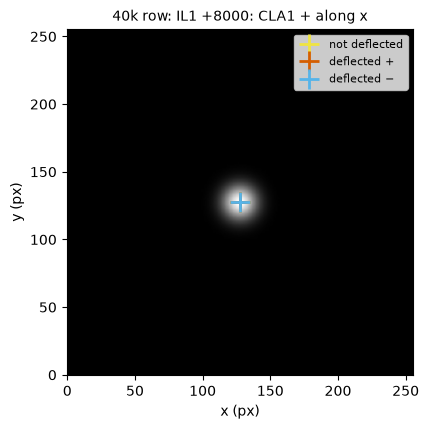

In [10]:
dry_run = True           # True: only print what this cell would do. False: do it.

with session.dry_run(dry_run):
    for number, setting in enumerate(measurement_plan, 1):
        print(f"{number}. {setting['name']}")
        about_this_setting = dict(number=number, setting=setting["name"], lenses=[float(v) for v in setting["lenses"]])

        session.set_lenses(setting["lenses"])
        frame_not_deflected = session.frame(role="not deflected", **about_this_setting)

        for deflector in ["CLA1", "CLA2"]:                  # CLA1 shifts the beam, CLA2 tilts it
            size = setting["deflections"][deflector]
            for direction, deflection in [("x", size), ("y", 1j * size)]:      # deflector units, x + iy
                session.deflect(deflector, +deflection)
                frame_plus = session.frame(role="deflected +", deflector=deflector, direction=direction,
                                           deflection_units=[deflection.real, deflection.imag], **about_this_setting)
                session.deflect(deflector, -deflection)
                frame_minus = session.frame(role="deflected -", deflector=deflector, direction=direction,
                                            deflection_units=[-deflection.real, -deflection.imag], **about_this_setting)
                if number == 2 and deflector == "CLA1" and direction == "x":     # the sample frames shown at the end
                    sample = dict(setting=setting["name"], not_deflected=frame_not_deflected, plus=frame_plus, minus=frame_minus)
            session.deflect(deflector, 0)

    session.restore()

if show_frames:
    beams = [("not deflected", find_beam(frame=sample["not_deflected"], background=session.dark_level)),
             ("deflected +", find_beam(frame=sample["plus"], background=session.dark_level)),
             ("deflected −", find_beam(frame=sample["minus"], background=session.dark_level))]
    show_frame(sample["plus"], beams=beams, title=f"{sample['setting']}: CLA1 + along x")

## 8. Fitting the lens model to the recording

**This section needs TemGym and JAX.** On the microscope PC without them, stop here and copy the
recording folder (`output/stage1_neoarm/`) to a computer that has them. There, run the first code cell
of this notebook, then this section from here, with `recording` set to the copied folder.

χ²/dof near 1 means the model fits to the wobble; far above 1, the worst-fitting measurements
say which measurements to look at.

In [11]:
# the recording just made; on another computer, the folder copied from the microscope
# (for example "output/stage1_neoarm/projection_response_2026-11-10_143000")
recording = session.folder

In [12]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"                      # JAX on the CPU (before it is imported): no GPU needed

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from jax.flatten_util import ravel_pytree
from scipy.optimize import least_squares

from temgym_core.components import HardEdgeSolenoid, Plane
from temgym_core.run import position_and_angle_response

jax.config.update("jax_enable_x64", True)
plt.rcParams.update({"font.size": 11, "axes.titlesize": 12, "axes.titleweight": "bold", "image.cmap": "gray"})
ORANGE, YELLOW = "#D55E00", "#F0E442"


### Model of the projection lenses (objective, IL1–IL3, PL1) in TemGym

The projection system as TemGym optics: the objective, IL1, IL2, IL3 and PL1 as five solenoids,
then the camera. A lens's strength is the angle the beam turns through in it. The fit knows each
lens by its gap from the one before, its length, and its strength at the 40k row; at another
setting IL1–PL1 scale with their DAC values (relative to the 40k row). The fitted numbers are
logarithms, so that gaps, lengths and strengths stay positive.

In [13]:
SIGNS = jnp.array([1.0, 1.0, 1.0, -1.0])                     # PL1's field points the other way


def lens_column(lenses, strengths):
    # TemGym components from the specimen to the camera, for IL1-PL1 at `strengths` (1 = the 40k row)
    gaps, lengths = jnp.exp(lenses["log_gaps"]), jnp.exp(lenses["log_lengths"])
    q = jnp.r_[lenses["objective"], SIGNS * jnp.exp(lenses["log_strengths_40k"]) * jnp.asarray(strengths)]
    entrances = jnp.cumsum(gaps[:5]) + jnp.r_[0.0, jnp.cumsum(lengths[:4])]
    return [*(HardEdgeSolenoid(z=entrances[i], length=lengths[i], q=q[i]) for i in range(5)),
            Plane(z=gaps.sum() + lengths.sum())]

### Fitting the lens model to the measured beam displacements

For each lens setting, TemGym gives A and B: how far the beam is displaced on the camera per metre of
shift and per radian of tilt at the specimen. A deflection of the shift deflector (CLA1) then displaces the
beam by A × (metres per deflector unit) × deflection, a deflection of the tilt deflector (CLA2) by B × (radians
per deflector unit) × deflection, both turned by the camera's rotation. The measured displacements are half the
difference of a + and − deflection (the beam's starting position cancels). The beam is found in each frame
by segmentation, and its centre is the intensity-weighted mean of its region: the electrons' mean
position, which linear optics displaces exactly by A × shift or B × tilt even if the beam's shape
changes. A frame whose beam is off the camera, reaches its edge, or is one of two similar regions
is not used.

Each deflector is deflected along its x axis and its y axis. A deflector's two axes need not be
square or the same size, and CLA2's need not point the same way as CLA1's, so each deflector has
its own axes in the fit; the specimen's x direction is CLA1's x axis. The fit is least squares, each misfit counted in units of the
wobble (measured from the repeats of the 40k row), starting from a rough projection
system. It tries the camera image mirrored and not, and keeps the better fit. At one HT the result is unscaled: it
predicts displacements, but the lens positions and the deflectors' metres and radians are not unique
yet (stage 2).

In [14]:
def read_log(folder):
    # the recording's log: one entry per saved frame
    return json.loads((Path(folder) / "log.json").read_text())


def load(folder):
    # For each + and - deflection at each lens setting, the displacement: how far the deflection shifts the beam's
    # centre on the camera (px, x + iy), as half the difference of the + and - beam centres (find_beam).
    # Deflections whose beam is not usable (off the camera, ...) are left out.
    log = read_log(folder)
    dark_frame = np.load(Path(folder) / next(entry for entry in log if entry["role"] == "dark")["file"])
    dark_level = float(np.median(dark_frame))

    measurements = []
    for number in sorted(set(entry["number"] for entry in log if "number" in entry)):
        for deflector in ["CLA1", "CLA2"]:
            for direction in ["x", "y"]:
                frames_of = {}
                for entry in log:
                    if entry.get("number") == number and entry.get("deflector") == deflector and entry.get("direction") == direction:
                        frames_of[entry["role"]] = entry                   # the last one, if retaken
                if "deflected +" not in frames_of or "deflected -" not in frames_of:
                    continue
                plus, minus = frames_of["deflected +"], frames_of["deflected -"]
                beam_plus = find_beam(frame=np.load(Path(folder) / plus["file"]), background=dark_level)
                beam_minus = find_beam(frame=np.load(Path(folder) / minus["file"]), background=dark_level)
                if beam_plus.usable and beam_minus.usable:
                    measurements.append(dict(number=number, setting=plus["setting"], deflector=deflector,
                                             direction=direction, lenses=plus["lenses"],
                                             deflection=complex(*plus["deflection_units"]),
                                             displacement=(beam_plus.centre - beam_minus.centre) / 2))
    return measurements


def beam_wobble(measurements):
    # The 40k row is measured three times with the same lenses and deflections, so its displacements should be
    # identical; how much they differ (standard deviation, px, in x or y) is the wobble.
    # Each average uses up one repeat; x and y count separately.
    differences = []
    averages = 0
    for deflector in ["CLA1", "CLA2"]:
        for direction in ["x", "y"]:
            repeats = np.array([m["displacement"] for m in measurements
                                if m["setting"] == "40k row" and m["deflector"] == deflector and m["direction"] == direction])
            differences.extend(repeats - repeats.mean())
            averages += 1
    return float(np.sqrt(np.sum(np.abs(differences) ** 2) / (2 * (len(differences) - averages))))


PIXEL = 110e-6                                                   # camera pixel (m), at binning 8

# A rough projection system to start from; the fit changes everything.
START = dict(
    log_gaps=np.log([0.0025, 0.19, 0.08, 0.05, 0.06, 0.34]),    # m: specimen to objective, objective to IL1, ..., PL1 to camera
    log_lengths=np.log([0.0005, 0.006, 0.004, 0.006, 0.0012]),   # m: objective, IL1, IL2, IL3, PL1
    objective=-0.40,                                             # strength (rad)
    log_strengths_40k=np.log([0.31, 0.34, 0.88, 0.59]),          # strengths (rad) of IL1-PL1 at the 40k row
)


def a_and_b_one_setting(lenses, strengths):
    return position_and_angle_response(lens_column(lenses, strengths))


# A and B (displacement on the camera per metre of shift and per radian of tilt at the specimen), at many settings at once
a_and_b = jax.jit(jax.vmap(a_and_b_one_setting, in_axes=(None, 0)))


def at_specimen(axes, deflection):
    # A deflection (deflector units, x + iy) as what it does at the specimen (x + iy): its x part along the
    # deflector's x axis, its y part along its y axis.
    #   axes["log_size"]: how much one unit along x does (log of m for CLA1, of rad for CLA2)
    #   axes["x_angle"]:  which way x points (rad, from the specimen's x; CLA1's x axis is the specimen's x)
    #   axes["y_axis"]:   the y axis relative to the x axis, as [x, y]; [0, 1] is square to it and the same size
    x_axis = jnp.exp(axes["log_size"] + 1j * axes.get("x_angle", 0.0))
    y_axis = x_axis * (axes["y_axis"][0] + 1j * axes["y_axis"][1])
    return x_axis * deflection.real + y_axis * deflection.imag


def predicted_displacements(params, data):
    # How far each deflection displaces the beam on the camera (px, x + iy).
    # A CLA1 deflection shifts the beam at the specimen, and A turns that shift into a displacement on the camera.
    # A CLA2 deflection tilts the beam at the specimen, and B turns that tilt into a displacement on the camera.
    a, b = a_and_b(params["lenses"], data["strengths"])
    shift_at_specimen = at_specimen(params["CLA1"], data["deflection"])                     # m, for CLA1
    tilt_at_specimen = at_specimen(params["CLA2"], data["deflection"])                      # rad, for CLA2
    on_camera = jnp.where(data["is_tilt"], b * tilt_at_specimen, a * shift_at_specimen)     # m
    return jnp.exp(1j * params["camera_rotation"]) * on_camera / PIXEL                      # turned by the camera, in px


def least_squares_fit(start, data):
    # The parameters that best predict the measured displacements, each misfit counted in wobbles.
    start_as_list, as_params = ravel_pytree(start)

    def misfits(parameter_list):
        misfit = (predicted_displacements(as_params(parameter_list), data) - data["displacement"]) / data["wobble"]
        return jnp.concatenate([misfit.real, misfit.imag])

    result = least_squares(jax.jit(misfits), np.asarray(start_as_list), jac=jax.jit(jax.jacfwd(misfits)),
                           method="lm", xtol=1e-12, ftol=1e-12, gtol=1e-12, max_nfev=2000)
    return dict(params=as_params(result.x), chi2=float(result.fun @ result.fun), dof=len(result.fun) - len(result.x))


def fit_response(folder):
    if not (Path(folder) / "log.json").exists():
        return print(f"nothing recorded in {folder} yet (the cells above were dry runs)")
    measurements = load(folder)
    lenses_40k = np.array(next(m["lenses"] for m in measurements if m["setting"] == "40k row"))
    data = dict(
        strengths=np.array([m["lenses"] for m in measurements]) / lenses_40k,   # IL1-PL1, relative to the 40k row
        is_tilt=np.array([m["deflector"] == "CLA2" for m in measurements]),     # CLA1 shifts, CLA2 tilts
        deflection=np.array([m["deflection"] for m in measurements]),           # deflector units, x + iy
        displacement=np.array([m["displacement"] for m in measurements]),       # px, x + iy
        wobble=beam_wobble(measurements),                                       # px
    )

    # Start from the rough projection system, with square deflector axes whose sizes give its displacements the
    # measured size.
    a, b = a_and_b(START, data["strengths"])
    a_or_b = np.abs(np.where(data["is_tilt"], b, a))
    size_per_unit = np.abs(data["displacement"]) * PIXEL / (a_or_b * np.abs(data["deflection"]))
    start = dict(lenses=START, camera_rotation=0.0,
                 CLA1=dict(log_size=np.log(np.median(size_per_unit[~data["is_tilt"]])), y_axis=np.array([0.0, 1.0])),
                 CLA2=dict(log_size=np.log(np.median(size_per_unit[data["is_tilt"]])), x_angle=0.0, y_axis=np.array([0.0, 1.0])))

    # The camera image may be mirrored, so fit both ways. Each fit starts at the camera rotation that best lines up the
    # start's CLA1 displacements with the measured ones, and CLA2's x axis turned to line up its displacements too;
    # and again half a turn round (a fit can get stuck the wrong way round).
    fits = []
    for mirrored in [False, True]:
        data_as_seen = dict(data, displacement=np.conj(data["displacement"]) if mirrored else data["displacement"])
        shift, tilt = ~data["is_tilt"], data["is_tilt"]
        start_seen = predicted_displacements(start, data_as_seen)
        rotation = np.angle(np.vdot(start_seen[shift], data_as_seen["displacement"][shift]))
        tilt_angle = np.angle(np.vdot(start_seen[tilt], data_as_seen["displacement"][tilt])) - rotation
        for half_turns in [0, 1]:
            first = dict(start, camera_rotation=rotation + half_turns * np.pi,
                         CLA2=dict(start["CLA2"], x_angle=tilt_angle - half_turns * np.pi))
            fit = least_squares_fit(first, data_as_seen)
            fits.append(dict(fit, mirrored=mirrored, data=data_as_seen))
    best = fits[int(np.argmin([fit["chi2"] for fit in fits]))]

    # The three measurements the model fits worst
    misfit = np.abs(predicted_displacements(best["params"], best["data"]) - best["data"]["displacement"])
    worst = []
    for i in np.argsort(misfit)[::-1][:3]:
        m = measurements[i]
        worst.append(f"{m['number']}. {m['setting']}, {m['deflector']} {m['direction']}: {misfit[i]:.3f} px")

    model = Model(params=best["params"], mirrored=best["mirrored"], lenses_40k=lenses_40k,
                  wobble_px=data["wobble"], chi2=best["chi2"], dof=best["dof"], worst=worst)
    (Path(folder) / "model.json").write_text(json.dumps(model, indent=1, default=as_list))
    return model


def predict(model, lenses, deflector, deflection):
    # How far a deflection (deflector units, x + iy) displaces the beam on the camera (px, x + iy) at IL1-PL1 = lenses.
    data = dict(strengths=np.array([lenses]) / model["lenses_40k"], is_tilt=np.array([deflector == "CLA2"]),
                deflection=np.array([deflection]))
    displacement = complex(predicted_displacements(model["params"], data)[0])
    if model["mirrored"]:
        return np.conj(displacement)
    return displacement



def deflection_for(model, lenses, deflector, wanted_px):
    # The deflection (deflector units, x + iy) that displaces the beam on the camera by wanted_px (x + iy) at
    # IL1-PL1 = lenses. The displacement is linear in the deflection, so one unit along x and one along y
    # give a 2 x 2 table (px per deflector unit) to invert.
    along_x = predict(model, lenses, deflector, 1)
    along_y = predict(model, lenses, deflector, 1j)
    table = np.array([[along_x.real, along_y.real],
                      [along_x.imag, along_y.imag]])
    x, y = np.linalg.solve(table, [np.real(wanted_px), np.imag(wanted_px)])
    return complex(x, y)

class Model(dict):
    # the fitted model; shown as a table
    def _repr_markdown_(self):
        rows = [("camera image mirrored", self["mirrored"])]
        for deflector in ["CLA1", "CLA2"]:
            y_axis = complex(*self["params"][deflector]["y_axis"])
            rows.append((f"{deflector} y axis, relative to its x axis",
                         f"turned {np.degrees(np.angle(y_axis)):.1f}°, {abs(y_axis):.3f} times as long"))
        cla2_x_angle = np.angle(np.exp(1j * float(self["params"]["CLA2"]["x_angle"])))
        rows.append(("CLA2 x axis, relative to CLA1's x axis", f"turned {np.degrees(cla2_x_angle):.1f}°"))
        rows.append(("wobble of the displacements, from the repeats (x or y)", f"{self['wobble_px']:.4f} px"))
        rows.append(("χ²/dof (≈ 1: fits to the wobble)", f"{self['chi2'] / self['dof']:.2f}"))
        rows.append(("worst-fitting measurements", "; ".join(self["worst"])))
        table = "| projection-system response (unscaled) | |\n|---|---|\n"
        for name, value in rows:
            table += f"| {name} | {value} |\n"
        return table


def as_list(array):
    return np.asarray(array).tolist()


### Plotting the recorded frames and the prediction test

In [15]:
def frames(folder, measurements=(1, 5, 11)):
    # at a few measurements: the frame with no deflection, and with each deflector deflected - and + along x and y;
    # + marks the beam centre found
    if not (Path(folder) / "log.json").exists():
        return print(f"nothing recorded in {folder} yet (the cells above were dry runs)")
    log = read_log(folder)
    dark_level = float(np.median(np.load(Path(folder) / log[0]["file"])))
    titles = ["not deflected", "CLA1 x −", "CLA1 x +", "CLA1 y −", "CLA1 y +", "CLA2 x −", "CLA2 x +", "CLA2 y −", "CLA2 y +"]
    fig, axes = plt.subplots(len(measurements), 9, figsize=(16, 2 * len(measurements)))
    for axes_row, number in zip(axes, measurements):
        entries = [entry for entry in log if entry.get("number") == number]
        chosen = [next(entry for entry in entries if entry["role"] == "not deflected")]
        for deflector in ["CLA1", "CLA2"]:
            for direction in ["x", "y"]:
                for role in ["deflected -", "deflected +"]:
                    chosen.append([e for e in entries if e.get("deflector") == deflector
                                   and e.get("direction") == direction and e["role"] == role][-1])
        images = [np.load(Path(folder) / entry["file"]) - dark_level for entry in chosen]
        frame_centre = (images[0].shape[1] - 1) / 2 * (1 + 1j)
        centres = np.array([find_beam(frame=image, background=0.0).centre for image in images]) + frame_centre
        for ax, image, centre, title in zip(axes_row, images, centres, titles):
            ax.imshow(np.sqrt(np.clip(image, 0, None)), origin="lower")
            ax.plot(centre.real, centre.imag, "+", color=YELLOW, ms=9)
            ax.set(xticks=[], yticks=[])
            ax.set_title(title if number == measurements[0] else "", fontweight="normal")
        axes_row[0].set_ylabel(f"{number}. {chosen[0]['setting']}", fontsize=9)
    fig.tight_layout()


def prediction_test(model, folder):
    # each deflection at the new settings: the predicted beam (orange: the no-deflection beam displaced as the model predicts) and
    # the measured centre (yellow +); the title says how far the beam moved and how far the prediction missed
    if not (Path(folder) / "log.json").exists():
        return print(f"nothing recorded in {folder} yet (the cells above were dry runs)")
    from scipy.ndimage import shift as shift_image
    log = read_log(folder)
    background = float(np.median(np.load(Path(folder) / log[0]["file"])))
    numbers = sorted(set(entry["number"] for entry in log if "number" in entry))
    panels = []
    for deflector in ["CLA1", "CLA2"]:
        for direction in ["x", "y"]:
            for role in ["deflected +", "deflected -"]:
                panels.append((deflector, direction, role))
    fig, axes = plt.subplots(len(numbers), len(panels), figsize=(16, 2.1 * len(numbers)))
    largest = 0.0
    for row, number in zip(axes, numbers):
        entries = [e for e in log if e.get("number") == number]
        base = np.load(Path(folder) / next(e for e in entries if e["role"] == "not deflected")["file"]) - background
        found = find_beam(frame=base, background=0.0)
        c0 = found.centre
        middle = (base.shape[1] - 1) / 2 * (1 + 1j)
        for ax, (deflector, direction, role) in zip(row, panels):
            e = [e for e in entries if e.get("deflector") == deflector and e.get("direction") == direction and e["role"] == role][-1]
            image = np.load(Path(folder) / e["file"]) - background
            measured_beam = find_beam(frame=image, background=0.0)
            measured = measured_beam.centre
            predicted = c0 + predict(model, e["lenses"], deflector, complex(*e["deflection_units"]))
            ax.imshow(np.sqrt(np.clip(image, 0, None)), origin="lower")
            predicted_beam = shift_image(base, ((predicted - c0).imag, (predicted - c0).real), order=1)
            ax.contour(predicted_beam, levels=[0.5 * predicted_beam.max()], colors=ORANGE, linewidths=1.2)
            for z, colour in ((predicted, ORANGE), (measured, YELLOW)):
                ax.plot((z + middle).real, (z + middle).imag, "+", color=colour, ms=10)
            ax.set(xticks=[], yticks=[])
            if not measured_beam.usable:
                ax.set_title("not used: " + measured_beam.problems[0].split(":")[0], fontsize=8, fontweight="normal")
                continue
            largest = max(largest, abs(measured - predicted))
            ax.set_title(f"{deflector} {direction}{role[-1]}: moved {abs(measured - c0):.0f} px\nmissed by {abs(measured - predicted):.3f} px", fontsize=8, fontweight="normal")
        row[0].set_ylabel(entries[0]["setting"], fontsize=10)
    fig.suptitle(f"Predicted (orange) and measured (yellow) beam at new lens settings; largest difference {largest:.3f} px",
                 x=0.02, ha="left", fontsize=12, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.97))

### Looking at the recorded frames and fitting

In [16]:
frames(recording)

nothing recorded in output/stage1_simulated/projection_response_2026-11-10_084412 yet (the cells above were dry runs)

In [17]:
model = fit_response(recording)
model

nothing recorded in output/stage1_simulated/projection_response_2026-11-10_084412 yet (the cells above were dry runs)


### Predicting the deflection needed for a chosen beam displacement

At any IL1–PL1 setting, the model says how far a deflection displaces the beam on the camera, and
the other way round: which deflection (in DAC units) displaces it by a chosen number of pixels. With
CLA1 that is a beam shift, with CLA2 a beam tilt. A deflection beyond ±32 767 units cannot be
made.

In [18]:
wanted_px = 50                                   # px, x + iy: here 50 px along the camera's x

if model is None:
    print("no model yet (the cells above were dry runs)")
else:
    lenses = model["lenses_40k"]                 # IL1-PL1 at the 40k row
    for deflector in ["CLA1", "CLA2"]:
        displacement = predict(model, lenses, deflector, 1000)
        print(f"{deflector} by 1000 units along x displaces the beam by {displacement.real:+.1f}, {displacement.imag:+.1f} px")
    for deflector in ["CLA1", "CLA2"]:
        deflection = deflection_for(model, lenses, deflector, wanted_px)
        possible = "" if max(abs(deflection.real), abs(deflection.imag)) <= 32767 else "   (beyond the DAC range)"
        print(f"to displace the beam by {wanted_px} px with {deflector}: {deflection.real:+.0f}, {deflection.imag:+.0f} units{possible}")

no model yet (the cells above were dry runs)


## 9. Testing the model at lens settings not used in the fit

The test plan: around each starting point, two lenses stepped at once (each by its step from
section 5), which the recording never did. At each of these settings the model picks the
deflections that should displace the beam by 30 px along the camera's x and along its y
(`deflection_for`); where 30 px needs more than 20 000 units (CLA2 near focus, CLA1 in DIFF) the
deflection is cut down to 20 000 units and the beam moves less. Then each deflection is made, +
and −, and the beam should land where the model says.

This needs the microscope and the model in the same Python session (TemGym on the microscope PC),
after sections 1–8.

In [19]:
wanted_px = 30                                   # how far each test deflection should displace the beam

# +1: the lens up by its step, -1: down by its step
two_lens_steps = [{"IL1": +1, "IL2": +1}, {"IL2": +1, "IL3": -1}, {"IL3": -1, "PL1": +1}, {"IL1": -1, "PL1": -1}]

test_plan = []

if model is None:
    print("no model yet (section 8 had nothing to fit), so no test plan")
else:
    for start in ["40k", "DIFF"]:
        for steps in two_lens_steps:
            lenses = lenses_at[start].copy()
            name = f"{start} row:"
            for i, lens in enumerate(LENSES):
                if lens in steps:
                    step = steps[lens] * lens_step_units[start, lens, steps[lens]]
                    lenses[i] = lenses[i] + step
                    name += f" {lens} {step:+d}"

            deflections = {}
            for deflector in ["CLA1", "CLA2"]:
                for direction, wanted in [("x", wanted_px), ("y", 1j * wanted_px)]:      # px on the camera, x + iy
                    deflection = deflection_for(model, lenses, deflector, wanted)        # deflector units, x + iy
                    largest = max(abs(deflection.real), abs(deflection.imag))
                    if largest > 20000:                                                  # cut down to 20 000 units
                        deflection = deflection * 20000 / largest
                    deflections[deflector, direction] = complex(round(deflection.real), round(deflection.imag))

            test_plan.append(dict(name=name, lenses=lenses, deflections=deflections))

for number, setting in enumerate(test_plan, 1):
    lenses = ", ".join(f"{lens} {value:.0f}" for lens, value in zip(LENSES, setting["lenses"]))
    print(f"{number}. {setting['name']:30s} {lenses}")
    for deflector in ["CLA1", "CLA2"]:
        x, y = setting["deflections"][deflector, "x"], setting["deflections"][deflector, "y"]
        print(f"      {deflector}: ±({x.real:+.0f}, {x.imag:+.0f}) units for camera x, "
              f"±({y.real:+.0f}, {y.imag:+.0f}) units for camera y")

no model yet (section 8 had nothing to fit), so no test plan


In [20]:
new = Session(TEM3=TEM3, detector=detector, take_frame=take_frame, lenses=LENSES, settle_s=settle_s,
              camera_name=camera_name, frame_shape=frame_shape, dtype=frame_dtype,
              folder=f"{output}/new_settings_{time.strftime('%Y-%m-%d_%H%M%S')}")    # a new folder each time

200 kV, X40000; IL1 41782, IL2 24862, IL3 35544, PL1 64000; CLA1 [32768, 32768], CLA2 [32768, 32768]


In [21]:
dry_run = True           # True: only print what this cell would do. False: do it.

with new.dry_run(dry_run):
    new.take_over_lenses()
    new.dark_frame()

    for number, setting in enumerate(test_plan, 1):
        print(f"{number}. {setting['name']}")
        about_this_setting = dict(number=number, setting=setting["name"], lenses=[float(v) for v in setting["lenses"]])

        new.set_lenses(setting["lenses"])
        frame_not_deflected = new.frame(role="not deflected", **about_this_setting)
        for deflector in ["CLA1", "CLA2"]:
            for direction in ["x", "y"]:
                deflection = setting["deflections"][deflector, direction]
                new.deflect(deflector, +deflection)
                frame_plus = new.frame(role="deflected +", deflector=deflector, direction=direction,
                          deflection_units=[deflection.real, deflection.imag], **about_this_setting)
                new.deflect(deflector, -deflection)
                frame_minus = new.frame(role="deflected -", deflector=deflector, direction=direction,
                          deflection_units=[-deflection.real, -deflection.imag], **about_this_setting)
                if number == 1 and deflector == "CLA1" and direction == "x":     # the sample frames shown at the end
                    sample = dict(setting=setting["name"], not_deflected=frame_not_deflected, plus=frame_plus, minus=frame_minus)
            new.deflect(deflector, 0)

    new.restore()

if show_frames and test_plan:
    beams = [("not deflected", find_beam(frame=sample["not_deflected"], background=new.dark_level)),
             ("deflected +", find_beam(frame=sample["plus"], background=new.dark_level)),
             ("deflected −", find_beam(frame=sample["minus"], background=new.dark_level))]
    show_frame(sample["plus"], beams=beams, title=f"{sample['setting']}: CLA1 + along x")

DRY RUN: nothing will change


  would switch free-lens control on for IL1, IL2, IL3, PL1 at IL1 41782, IL2 24862, IL3 35544, PL1 64000


  would blank the beam, take a dark frame, unblank


  would put everything back as at opening


In [22]:
prediction_test(model, new.folder)

nothing recorded in output/stage1_simulated/new_settings_2026-11-10_084414 yet (the cells above were dry runs)
